In [181]:
df.isnull().sum()

match_id               0
season                 0
phase                  0
match_no               0
date                   0
venue                  0
batting_team           0
bowling_team           0
innings                0
over                   0
striker                0
bowler                 0
runs_of_bat            0
extras                 0
wide                   0
legbyes                0
byes                   0
noballs                0
wicket_type         3325
player_dismissed    3329
fielder             3365
dtype: int64

## how many matches are played ? 

In [210]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
df=pd.read_csv('ipl.csv')
df['wicket_type'].unique()
df

,match_id,season,phase,match_no,date,venue,batting_team,bowling_team,innings,over,...,bowler,runs_of_bat,extras,wide,legbyes,byes,noballs,wicket_type,player_dismissed,fielder
0,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.1,...,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN
1,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.2,...,Jacob Duffy,1,0,0,0,0,0,NaN,NaN,NaN
2,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.3,...,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN
3,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.4,...,Jacob Duffy,6,0,0,0,0,0,NaN,NaN,NaN
4,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.5,...,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3512,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,17.2,...,Romario Shepherd,1,0,0,0,0,0,NaN,NaN,NaN
3513,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,17.3,...,Romario Shepherd,1,0,0,0,0,0,NaN,NaN,NaN
3514,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,17.4,...,Romario Shepherd,1,0,0,0,0,0,NaN,NaN,NaN
3515,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,17.5,...,Romario Shepherd,6,0,0,0,0,0,NaN,NaN,NaN


In [182]:
df['match_id'].nunique()

16

## what and how many teams are playing?


In [183]:
df['batting_team'].unique()

array(['SRH', 'RCB', 'KKR', 'MI', 'CSK', 'RR', 'GT', 'PBKS', 'LSG', 'DC'],
      dtype=object)

In [184]:
df['batting_team'].nunique()

10

## feature engineering---create useful columns?


In [185]:
df['total_runs']=df['runs_of_bat']+df['extras']
df['is_six']=0
df['is_four']=0
df['wicket_type'].unique()
df.loc[df['player_dismissed'].notna(),
    ['player_dismissed','wicket_type']]
df['wicket_type'].value_counts(dropna=False)
df.loc[df['runs_of_bat']==6 ,'is_six' ]=1
df.loc[df['runs_of_bat']==4 ,'is_four']=1
df.head()

,match_id,season,phase,match_no,date,venue,batting_team,bowling_team,innings,over,...,wide,legbyes,byes,noballs,wicket_type,player_dismissed,fielder,total_runs,is_six,is_four
0,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.1,...,0,0,0,0,NaN,NaN,NaN,0,0,0
1,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.2,...,0,0,0,0,NaN,NaN,NaN,1,0,0
2,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.3,...,0,0,0,0,NaN,NaN,NaN,0,0,0
3,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.4,...,0,0,0,0,NaN,NaN,NaN,6,1,0
4,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.5,...,0,0,0,0,NaN,NaN,NaN,0,0,0


## change in columns---


In [186]:
df['over']=df['over']+1
def get_phase(over):
    if over <=6:
        return 'powerplay(1-6)'
    elif over <=15:
        return 'middle(7-15)'
    else:
        return 'death(16-20)'
df['phase_group']=df['over'].apply(get_phase)
df
    

,match_id,season,phase,match_no,date,venue,batting_team,bowling_team,innings,over,...,legbyes,byes,noballs,wicket_type,player_dismissed,fielder,total_runs,is_six,is_four,phase_group
0,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.1,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
1,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.2,...,0,0,0,NaN,NaN,NaN,1,0,0,powerplay(1-6)
2,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.3,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
3,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.4,...,0,0,0,NaN,NaN,NaN,6,1,0,powerplay(1-6)
4,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.5,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3512,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.2,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3513,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.3,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3514,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.4,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3515,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.5,...,0,0,0,NaN,NaN,NaN,6,1,0,death(16-20)


## Bating Analysis---
which team scored the most runs  ?

In [187]:
edf=df.groupby('batting_team').agg(
    total=('total_runs','sum')
).reset_index()
edf=edf.sort_values('total',ascending=False)
edf

,batting_team,total
8,RR,690
7,RCB,654
3,KKR,586
9,SRH,585
2,GT,576
0,CSK,544
1,DC,516
5,MI,509
4,LSG,483
6,PBKS,374


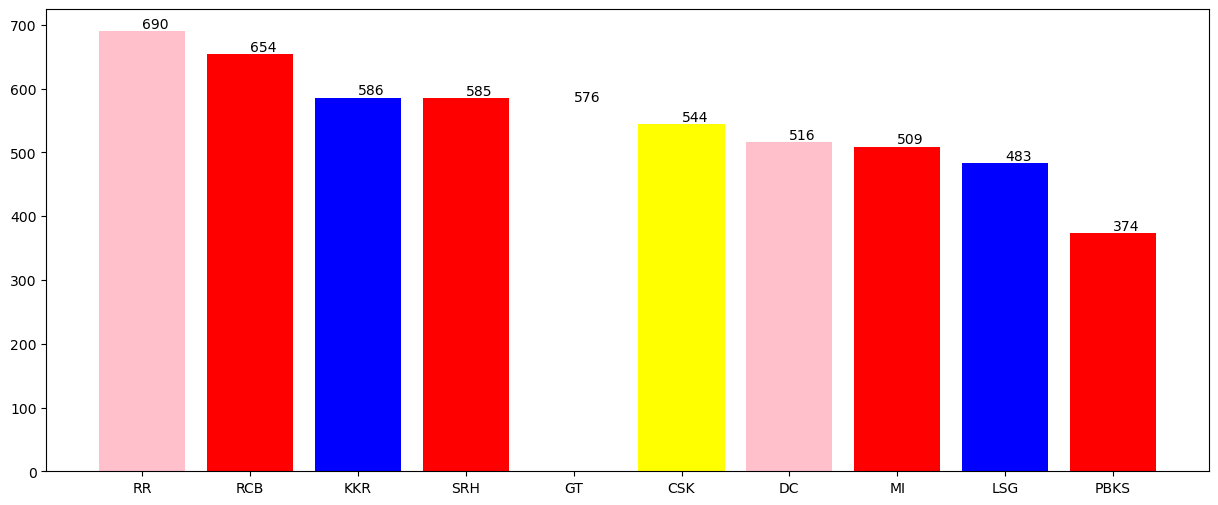

In [188]:
plt.figure(figsize=(15,6))
plt.bar(edf['batting_team'],edf['total'],color =['pink','red','blue','red','white','yellow'])
for x,y in zip(edf['batting_team'],edf['total']):
     plt.text(x=x,y=y,s=y,va='bottom')
plt.show()
        


## Team with most six and fours---


In [189]:
edf=df.groupby("batting_team").agg(
    nos=('is_six','sum'),
    nof=('is_four','sum')
).reset_index()
edf['score by boundaries']=edf['nos']+edf['nof']
edf


,batting_team,nos,nof,score by boundaries
0,CSK,23,50,73
1,DC,22,50,72
2,GT,23,55,78
3,KKR,24,57,81
4,LSG,19,44,63
5,MI,23,50,73
6,PBKS,23,29,52
7,RCB,39,51,90
8,RR,42,59,101
9,SRH,29,50,79


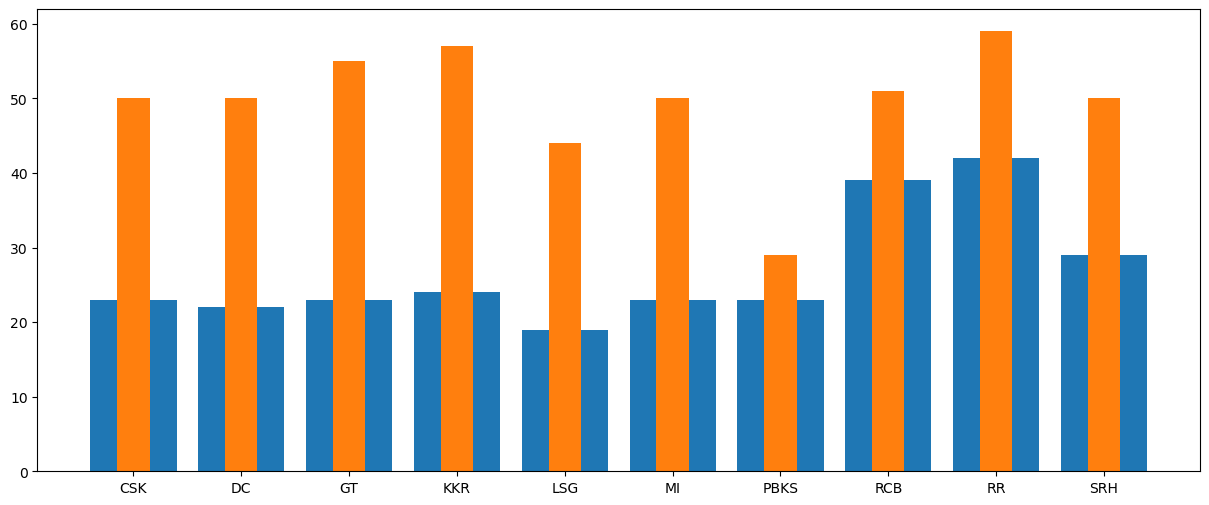

In [190]:
plt.figure(figsize=(15,6))
plt.bar(edf['batting_team'],edf['nos'])
plt.bar(edf['batting_team'],edf['nof'],width=0.3)
plt.show()

## How many runs did each team score in powerplay,Middle and Death overs??



In [191]:
edf=df.groupby(['batting_team','phase_group']).agg(
    total=('total_runs','sum') 
).reset_index()
edf=edf.sort_values(['batting_team','total'],ascending=False) 
edf

,batting_team,phase_group,total
28,SRH,middle(7-15),264
27,SRH,death(16-20),201
29,SRH,powerplay(1-6),120
25,RR,middle(7-15),324
26,RR,powerplay(1-6),265
24,RR,death(16-20),101
22,RCB,middle(7-15),278
21,RCB,death(16-20),208
23,RCB,powerplay(1-6),168
19,PBKS,middle(7-15),153


In [192]:
edf=df.pivot_table(index='batting_team',columns='phase_group',values='total_runs',aggfunc='sum').reset_index()
edf


phase_group,batting_team,death(16-20),middle(7-15),powerplay(1-6)
0,CSK,171,224,149
1,DC,156,252,108
2,GT,160,261,155
3,KKR,148,238,200
4,LSG,148,211,124
5,MI,111,256,142
6,PBKS,109,153,112
7,RCB,208,278,168
8,RR,101,324,265
9,SRH,201,264,120


### Batsman analyis----

top 10 scores in ipl 2026......

In [193]:
edf=df.groupby('striker').agg(
    total=('total_runs','sum')
).reset_index()   
edf


,striker,total
0,Abdul Samad,59
1,Abhishek Sharma,61
2,Aiden Markram,80
3,Ajinkya Rahane,131
4,Angkrish Raghuvanshi,163
...,...,...
104,Vipraj Nigam,12
105,Virat Kohli,142
106,Washington Sundar,81
107,Xavier Bartlett,11


In [194]:
edf=edf.sort_values('total',ascending=False).head(10)
edf

,striker,total
101,Vaibhav Sooryavanshi,204
108,Yashasvi Jaiswal,193
22,Dhruv Jurel,185
80,Sameer Rizvi,175
4,Angkrish Raghuvanshi,163
29,Heinrich Klaasen,150
66,Rajat Patidar,149
105,Virat Kohli,142
21,Devdutt Padikkal,136
3,Ajinkya Rahane,131


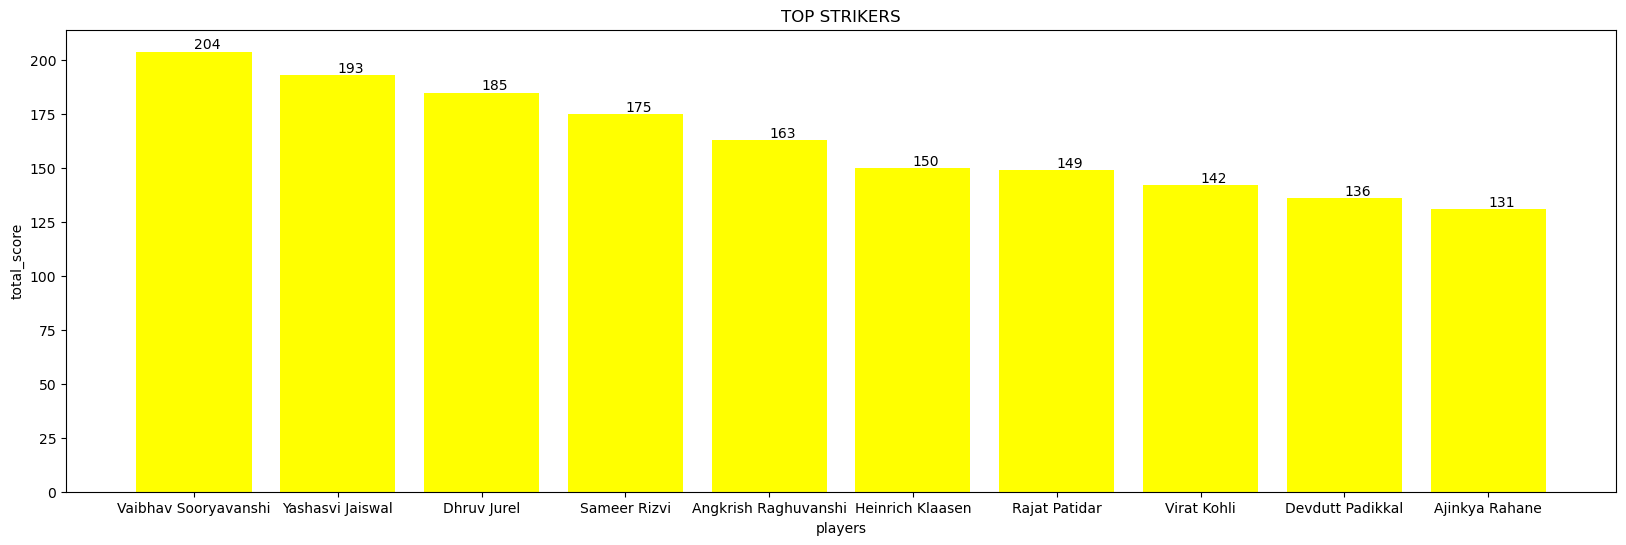

In [195]:
plt.figure(figsize=(20,6))
plt.bar(edf['striker'],edf['total'],color='yellow')
plt.title('TOP STRIKERS')
plt.xlabel('players')
plt.ylabel('total_score')

for x,y in zip(edf['striker'],edf['total']):
    plt.text(x=x,y=y,s=y,va='bottom')
plt.show()

### Top Batsman (Boundaries)

In [196]:
edf=df.groupby('striker').agg(
    total=('is_six','sum')
).reset_index()
edf=edf.sort_values('total',ascending=False).head(10)
edf

,striker,total
101,Vaibhav Sooryavanshi,18
66,Rajat Patidar,13
80,Sameer Rizvi,11
108,Yashasvi Jaiswal,10
77,Ryan Rickelton,9
96,Tim David,9
22,Dhruv Jurel,8
52,Mukul Choudhary,7
3,Ajinkya Rahane,7
73,Rohit Sharma,7


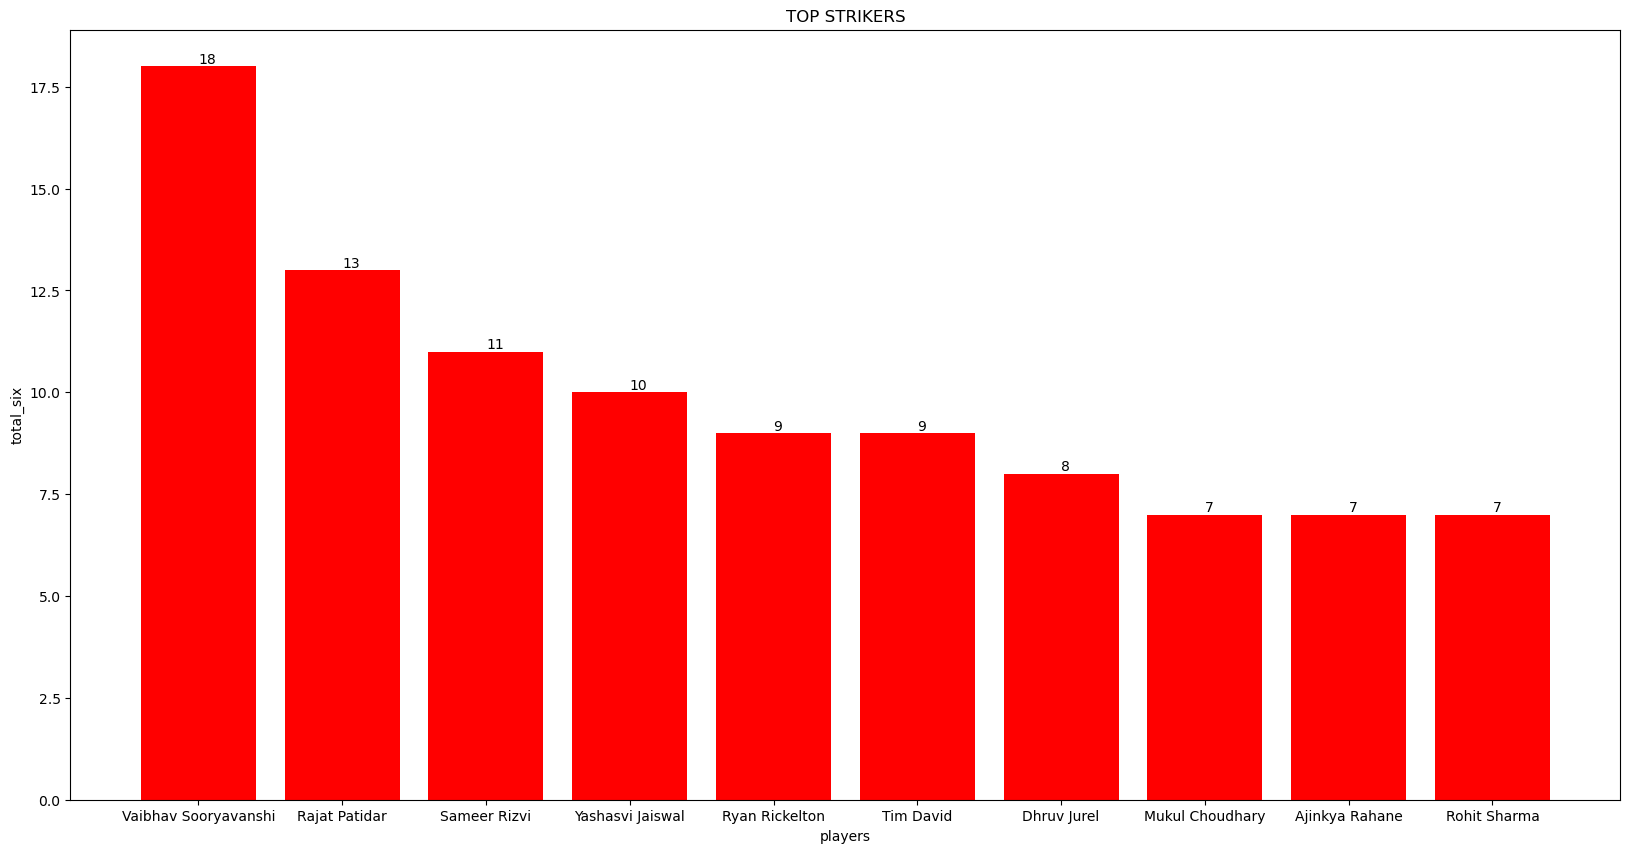

In [197]:
plt.figure(figsize=(20,10))
plt.bar(edf['striker'],edf['total'],color='red')
plt.title('TOP STRIKERS')
plt.xlabel('players')
plt.ylabel('total_six')
for x,y in zip(edf['striker'],edf['total']):
    plt.text(x=x,y=y,s=y,va='bottom')
plt.show()

### Strike rate for top 10 batsman---

1=formula=total_score/ball_faced*100
2=white ball != faced ball

In [198]:
legal_balls = df.loc[df['extras']==0]
legal_balls

,match_id,season,phase,match_no,date,venue,batting_team,bowling_team,innings,over,...,legbyes,byes,noballs,wicket_type,player_dismissed,fielder,total_runs,is_six,is_four,phase_group
0,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.1,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
1,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.2,...,0,0,0,NaN,NaN,NaN,1,0,0,powerplay(1-6)
2,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.3,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
3,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.4,...,0,0,0,NaN,NaN,NaN,6,1,0,powerplay(1-6)
4,202601,2026,Group Stage,1,"Mar 28, 2026","M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,1.5,...,0,0,0,NaN,NaN,NaN,0,0,0,powerplay(1-6)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3512,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.2,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3513,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.3,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3514,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.4,...,0,0,0,NaN,NaN,NaN,1,0,0,death(16-20)
3515,202616,2026,Group Stage,16,"Apr 10, 2026","Barsapara Cricket Stadium, Guwahati",RR,RCB,2,18.5,...,0,0,0,NaN,NaN,NaN,6,1,0,death(16-20)


In [199]:
edf= df.groupby('striker').agg(
    runs=('runs_of_bat','sum'),
    balls=('runs_of_bat','count')
).reset_index()
edf=edf.loc[edf['balls']>=30]
edf['strike_rate']=(edf['runs']/edf['balls'])*100
edf=edf.sort_values('strike_rate',ascending=False).head(10)
edf['strike_rate']=edf['strike_rate'].round()
edf

,striker,runs,balls,strike_rate
101,Vaibhav Sooryavanshi,200,78,256.0
96,Tim David,99,46,215.0
21,Devdutt Padikkal,125,63,198.0
24,Finn Allen,80,41,195.0
66,Rajat Patidar,141,74,191.0
82,Sarfaraz Khan,99,52,190.0
30,Ishan Kishan,96,52,185.0
22,Dhruv Jurel,176,102,173.0
105,Virat Kohli,129,76,170.0
77,Ryan Rickelton,98,59,166.0


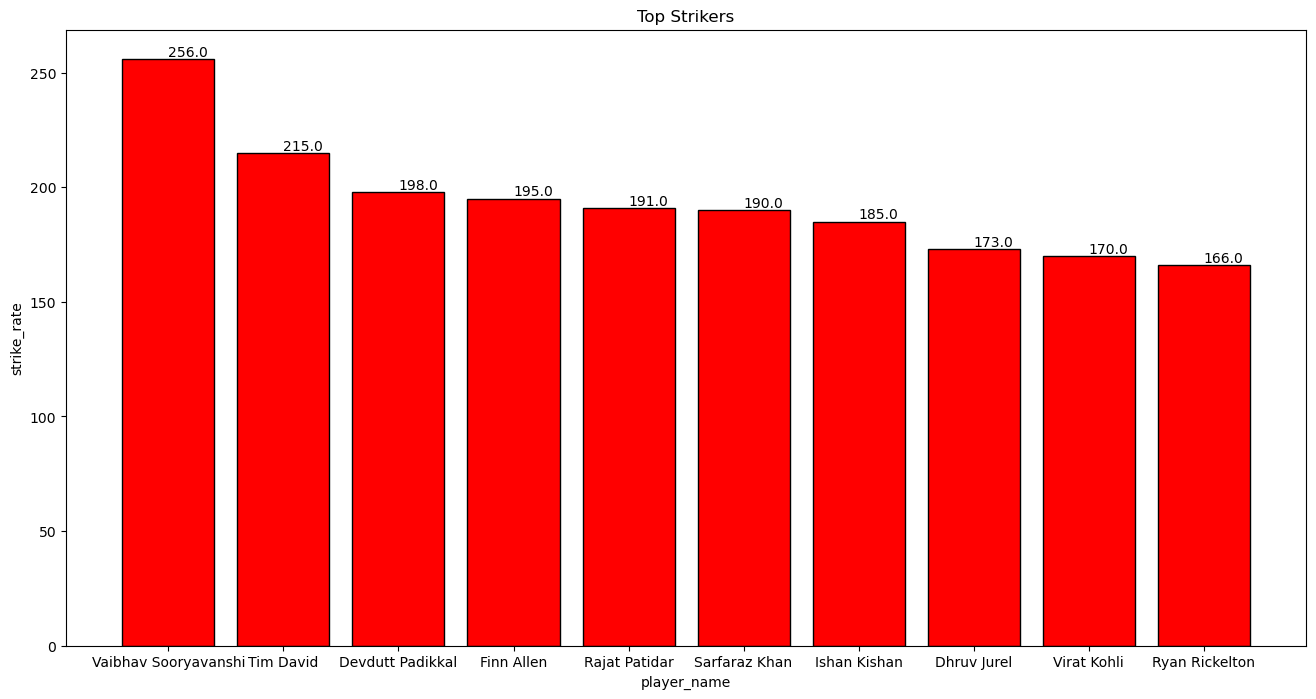

In [200]:
plt.figure(figsize=(16,8))
plt.bar(edf['striker'],edf['strike_rate'],color='red',edgecolor='black')
plt.title('Top Strikers')
plt.xlabel('player_name')
plt.ylabel('strike_rate')
for x,y in zip(edf['striker'],edf['strike_rate']):
    plt.text(x=x,y=y,s=y,va='bottom')
plt.show()

### Which bowler has best economy rate

runs give per over

economy rate=total_runs/balls*6

In [201]:
legal_balls=df.loc[(df['wide']==0) &(df['noballs']==0)]
legal_balls
edf=df.groupby('bowler').agg(
    total=('runs_of_bat','sum'),
    balls=('runs_of_bat','count')
).reset_index()
edf=edf.loc[edf['balls']>=18]
edf['economy_rate']=edf['total']/edf['balls']*6
edf=edf.sort_values('economy_rate',ascending=False).head(10)
edf
        

,bowler,total,balls,economy_rate
25,Jamie Overton,56,24,14.000000
17,David Payne,69,31,13.354839
39,Matt Henry,129,61,12.688525
59,Romario Shepherd,90,43,12.558140
71,Varun Chakaravarthy,77,38,12.157895
2,Abhinandan Singh,120,60,12.000000
62,Shardul Thakur,112,58,11.586207
16,Corbin Bosch,38,20,11.400000
49,Navdeep Saini,36,19,11.368421
41,Mayank Markande,35,19,11.052632


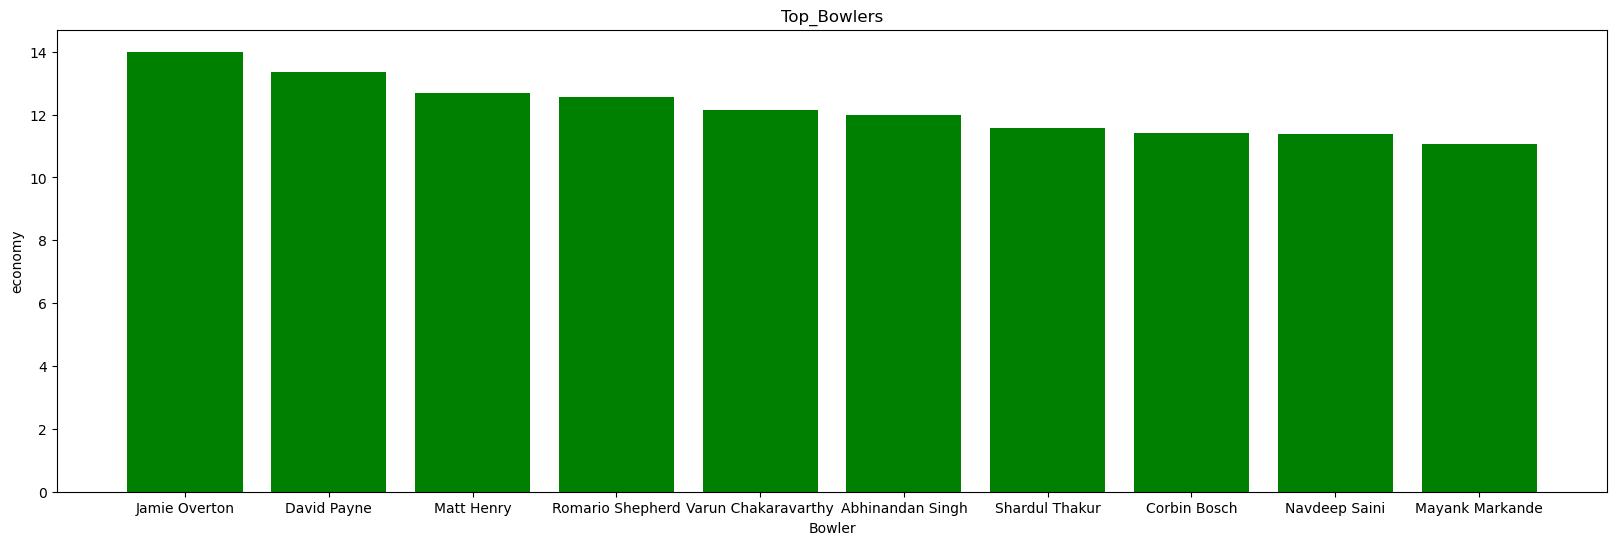

In [202]:
plt.figure(figsize=(20,6))
plt.bar(edf['bowler'],edf['economy_rate'],color='green')
plt.title('Top_Bowlers')
plt.xlabel('Bowler')
plt.ylabel('economy')
plt.show()

### How are batsman getting out(wicket type breakdown)

In [203]:
edf=df['wicket_type'].value_counts().reset_index()
edf

,wicket_type,count
0,caught,141
1,bowled,29
2,runout,13
3,lbw,7
4,stumped,2


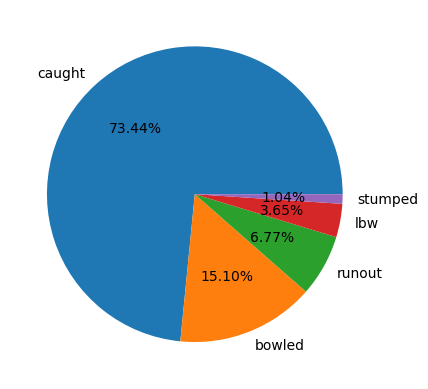

Index(['match_id', 'season', 'phase', 'match_no', 'date', 'venue',
       'batting_team', 'bowling_team', 'innings', 'over', 'striker', 'bowler',
       'runs_of_bat', 'extras', 'wide', 'legbyes', 'byes', 'noballs',
       'wicket_type', 'player_dismissed', 'fielder', 'total_runs', 'is_six',
       'is_four', 'phase_group'],
      dtype='object')

In [204]:
plt.pie(edf['count'],labels=edf['wicket_type'],autopct='%0.2f%%')
plt.show()
df.columns

### Over by Over analysis

###Average run rate over by ober

In [205]:
df['over_number']=df['over'].astype(int)
edf =df.groupby('over_number').agg(
    avg_runs=('total_runs','mean'),
    total=('total_runs','sum')
).reset_index()    
edf['avg_runs']=edf['avg_runs'].round(2)
edf
    

,over_number,avg_runs,total
0,1,1.48,289
1,2,1.46,291
2,3,1.57,314
3,4,1.65,311
4,5,1.78,338
5,6,1.68,313
6,7,1.48,271
7,8,1.49,278
8,9,1.62,302
9,10,1.25,233


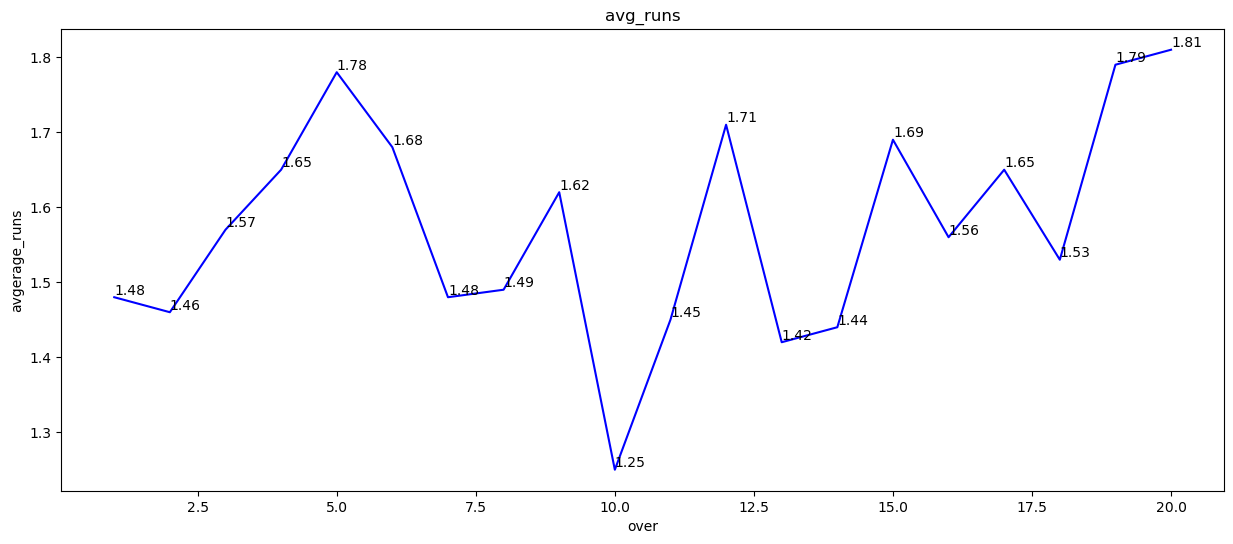

In [206]:
plt.figure(figsize=(15,6))
plt.plot(edf['over_number'],edf['avg_runs'],color='blue')
plt.title('avg_runs')
plt.xlabel('over')
plt.ylabel('avgerage_runs')
for x,y in zip(edf['over_number'],edf['avg_runs']):
    plt.text(x=x,y=y,s=y,va='bottom')
plt.show()


### Which team is better in powerplay.middle and death---

In [207]:
edf=df.groupby(['batting_team','phase_group']).agg(
    total=('total_runs','sum')
).reset_index()
edf=df.pivot_table(index ='batting_team',columns='phase_group',values='total_runs',aggfunc='sum').reset_index()
edf
    

phase_group,batting_team,death(16-20),middle(7-15),powerplay(1-6)
0,CSK,171,224,149
1,DC,156,252,108
2,GT,160,261,155
3,KKR,148,238,200
4,LSG,148,211,124
5,MI,111,256,142
6,PBKS,109,153,112
7,RCB,208,278,168
8,RR,101,324,265
9,SRH,201,264,120


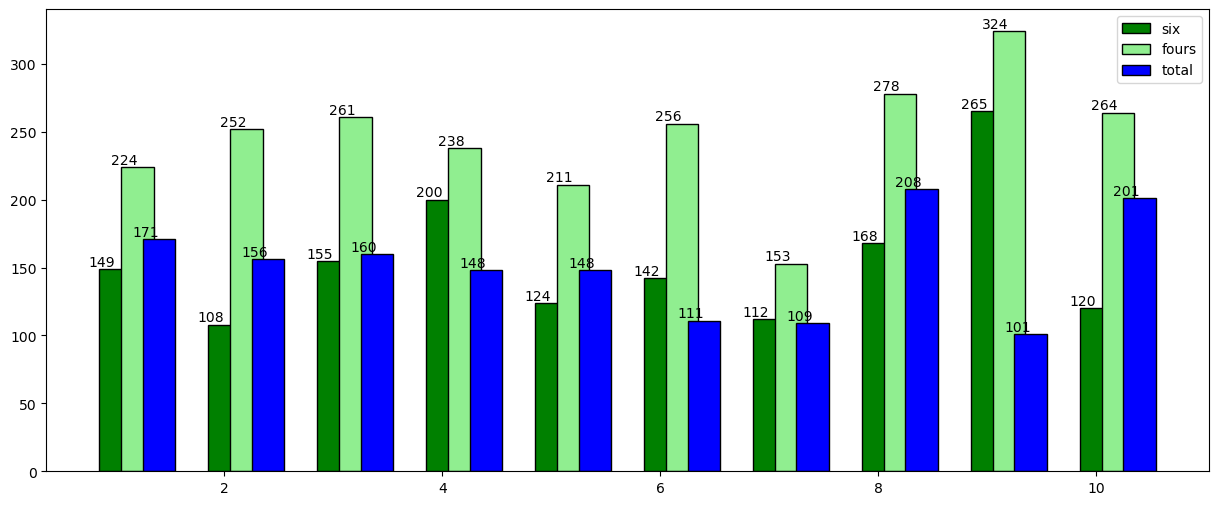

In [213]:
plt.figure(figsize=(15,6))
xval=np.arange(1,11)
plt.bar(xval,edf['powerplay(1-6)'],width=0.3,color='green',label='six',edgecolor='black')
plt.bar(xval+0.2,edf['middle(7-15)'],width=0.3,color='lightgreen',label='fours',edgecolor='black')
plt.bar(xval+0.4,edf['death(16-20)'],width=0.3,color='blue',label='total',edgecolor='black')
plt.legend()

for x,y in zip(xval,edf['powerplay(1-6)']):
    plt.text(x=x,y=y,s=y,va='bottom',ha='right')
for x,y in zip(xval+0.2,edf['middle(7-15)']):
    plt.text(x=x,y=y,s=y,va='bottom',ha='right')
for x,y in zip(xval+0.4,edf['death(16-20)']):
    plt.text(x=x,y=y,s=y,va='bottom',ha='right')    
plt.show()    
    
    